# Modell-Test und Segmentierungs-Auswertung
Das trainierte Modell wird auf diesem Notebook geladen und die Deployment-Logik wird auf ein ungesehenes Testbild angewendet. So wird der objektive IoU-Score (Intersection over Union) berechnet. Dieser wird zur Bewertung der Segmentierungsqualität verwendet.

In [11]:
import os
import sys
import importlib.util
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Hauptordner zum Python-Pfad hinzufügen, damit die src-Module gefunden werden
sys.path.append(os.path.abspath("."))

### 1. Deployment-Skript dynamisch laden
Da das Skript `04_deploy.py` mit einer Zahl beginnt, wird `importlib` für den Import genutzt, da ein normales `import` in Python bei Zahlen am Anfang nicht funktioniert.

In [12]:
# Deployment-Modul laden
deploy_script_path = Path("src/ML/04_deploy.py")
spec_deploy = importlib.util.spec_from_file_location("deploy_module", deploy_script_path)
deploy_module = importlib.util.module_from_spec(spec_deploy)
spec_deploy.loader.exec_module(deploy_module)
deploy_model_on_file = deploy_module.deploy_model_on_file

# Postprocessing-Modul laden
post_script_path = Path("src/ML/05_postprocessing.py")
spec_post = importlib.util.spec_from_file_location("post_module", post_script_path)
post_module = importlib.util.module_from_spec(spec_post)
spec_post.loader.exec_module(post_module)
apply_morphological_filters = post_module.apply_morphological_filters

print("Deployment- und Postprocessing-Module erfolgreich geladen!")

Deployment- und Postprocessing-Module erfolgreich geladen!


### 2. Segmentierung auf ungesehene Daten anwenden

In [13]:
# Pfade definieren (Passe die Testdatei an, falls noetig)
base_data_path = Path("KIS2_Data")
test_file = base_data_path / "defect" / "Simulation_Data10004.hdf5"
model_path = Path("src/ML/saved_models/best_logistic_regression.pkl")

print(f"Starte Inferenz fuer: {test_file.name} ...")

# Vorhersage mit unserer Funktion aus 04_deploy.py durchführen
predicted_mask, true_mask = deploy_model_on_file(test_file, model_path)

print("Inferenz erfolgreich beendet!")

Starte Inferenz fuer: Simulation_Data10004.hdf5 ...
Lade und verarbeite Datei: Simulation_Data10004.hdf5
Vorverarbeitung abgeschlossen. Starte KI-Inferenz...
Inferenz erfolgreich beendet!


### 3. IoU-Score berechnen (Intersection over Union)
Der IoU-Score misst, wie perfekt sich unsere vorhergesagte Maske mit der echten Defektmaske überschneidet. 100% wäre eine absolut fehlerfreie Vorhersage.

In [ ]:
true_mask_binary = np.where(true_mask > 0, 1, 0)

# --- 1. Morphologischen Filter anwenden ---
predicted_mask_cleaned = apply_morphological_filters(predicted_mask, filter_size=3)

# --- 2. IoU-Funktion definieren ---
def calculate_iou(mask_true, mask_pred):
    intersection = np.logical_and(mask_true, mask_pred)
    union = np.logical_or(mask_true, mask_pred)
    return 1.0 if np.sum(union) == 0 else np.sum(intersection) / np.sum(union)

# --- 3. Scores berechnen ---
iou_raw = calculate_iou(true_mask_binary, predicted_mask)
iou_clean = calculate_iou(true_mask_binary, predicted_mask_cleaned)

print(f"====== ERGEBNIS ======")
print(f"IoU-Score (Rohvorhersage):  {iou_raw * 100:.2f} %")
print(f"IoU-Score (Gefiltert):      {iou_clean * 100:.2f} %")
print(f"Verbesserung:               {+(iou_clean - iou_raw) * 100:.2f} Prozentpunkte")

====== ERGEBNIS ======
IoU-Score (Rohvorhersage):  81.73 %
IoU-Score (Gefiltert):      82.53 %
Verbesserung:               0.79 Prozentpunkte


### 4. Visuelle Auswertung (Ground Truth vs. KI vs. Error Map)
Wir plotten das Ergebnis und eine Error-Map. 
*   **Dunkelrot (1):** Falscher Alarm (False Positive - Rauschen als Defekt erkannt)
*   **Dunkelblau (-1):** Übersehener Defekt (False Negative)
*   **Grau/Weiß (0):** Korrekt klassifiziert

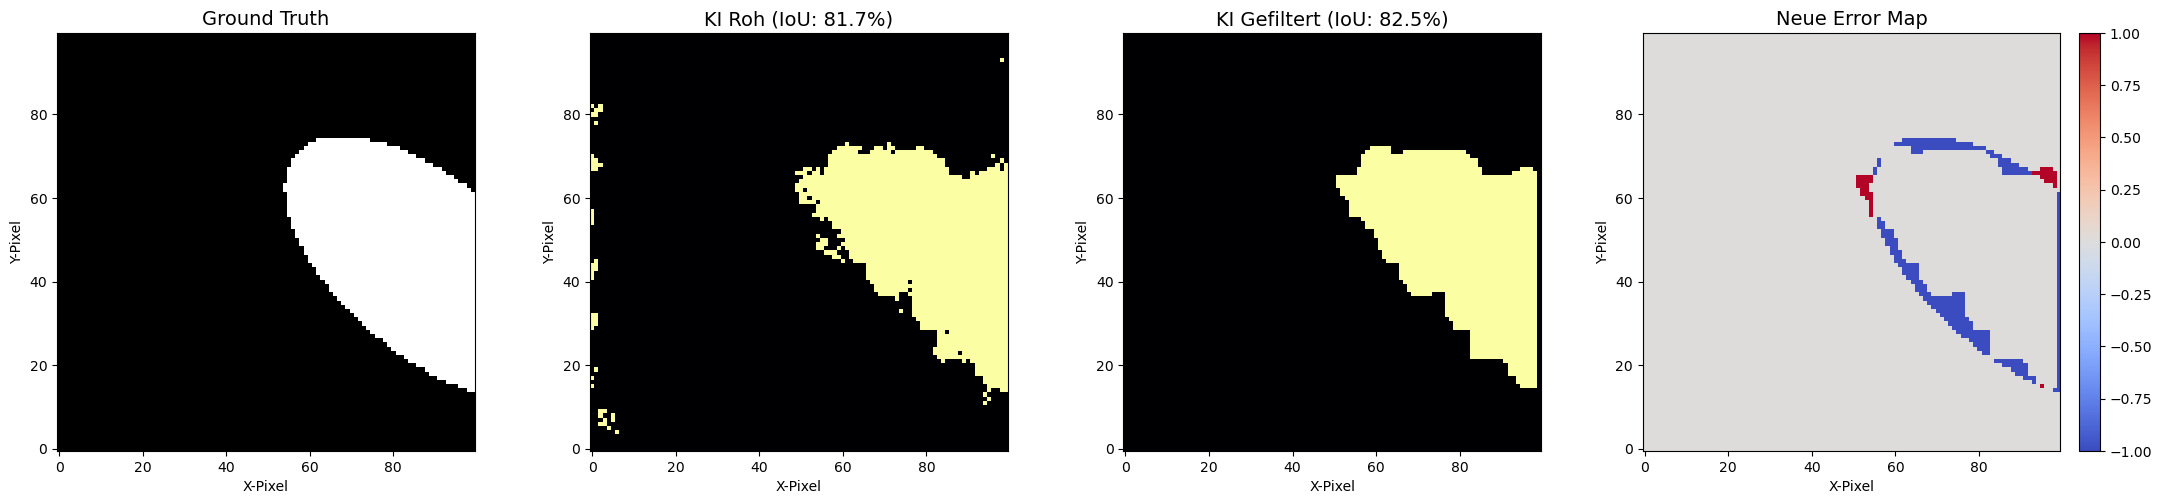

In [15]:
# Fehlerkarte auf Basis der BEREINIGTEN Maske
error_map_cleaned = predicted_mask_cleaned.astype(int) - true_mask_binary.astype(int)

fig, axes = plt.subplots(1, 4, figsize=(22, 5))

# Alle physikalischen Koordinaten zeigen nach oben (origin='lower')
axes[0].imshow(true_mask_binary, cmap='gray', origin='lower')
axes[0].set_title('Ground Truth', fontsize=14)

axes[1].imshow(predicted_mask, cmap='inferno', origin='lower')
axes[1].set_title(f'KI Roh (IoU: {iou_raw*100:.1f}%)', fontsize=14)

axes[2].imshow(predicted_mask_cleaned, cmap='inferno', origin='lower')
axes[2].set_title(f'KI Gefiltert (IoU: {iou_clean*100:.1f}%)', fontsize=14)

im = axes[3].imshow(error_map_cleaned, cmap='coolwarm', origin='lower', vmin=-1, vmax=1)
axes[3].set_title('Neue Error Map', fontsize=14)
fig.colorbar(im, ax=axes[3], fraction=0.046, pad=0.04)

for ax in axes:
    ax.set_xlabel('X-Pixel')
    ax.set_ylabel('Y-Pixel')

plt.tight_layout()
plt.show()